In [6]:
# %% Paso 1: Importación de paquetes ============================

# Rutas relativas
from pathlib import Path

# Manipulación de datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pruebas estadísticas y gráficos Q-Q de Scipy
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels (FAC/FACP, pruebas de diagnóstico y SARIMAX)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss


# %% Configuración de ruta relativa ============================

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / "datos"

print("Directorio raíz del proyecto:", BASE_DIR)
print("Carpeta de datos lista en:", DATA_DIR)


Directorio raíz del proyecto: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II
Carpeta de datos lista en: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II\datos


In [7]:
# Carga de la serie con ruta relativa
ruta_csv = DATA_DIR / "serie_economica.csv"

# Leer CSV parseando la columna de fechas de la FRED
df = pd.read_csv(ruta_csv, parse_dates=['observation_date'], index_col='observation_date')
df.columns = ['precio_gasolina']

# Convertir valores a numérico y eliminar nulos si existieran
df['precio_gasolina'] = pd.to_numeric(df['precio_gasolina'], errors='coerce')
df = df.dropna()

# Mostrar el total de observaciones
print(f"Número total de observaciones (T): {len(df)}")

# Visualizar las primeras filas del DataFrame
df.head()


Número total de observaciones (T): 1882


,precio_gasolina
observation_date,
1990-08-20,1.191
1990-08-27,1.245
1990-09-03,1.242
1990-09-10,1.252
1990-09-17,1.266


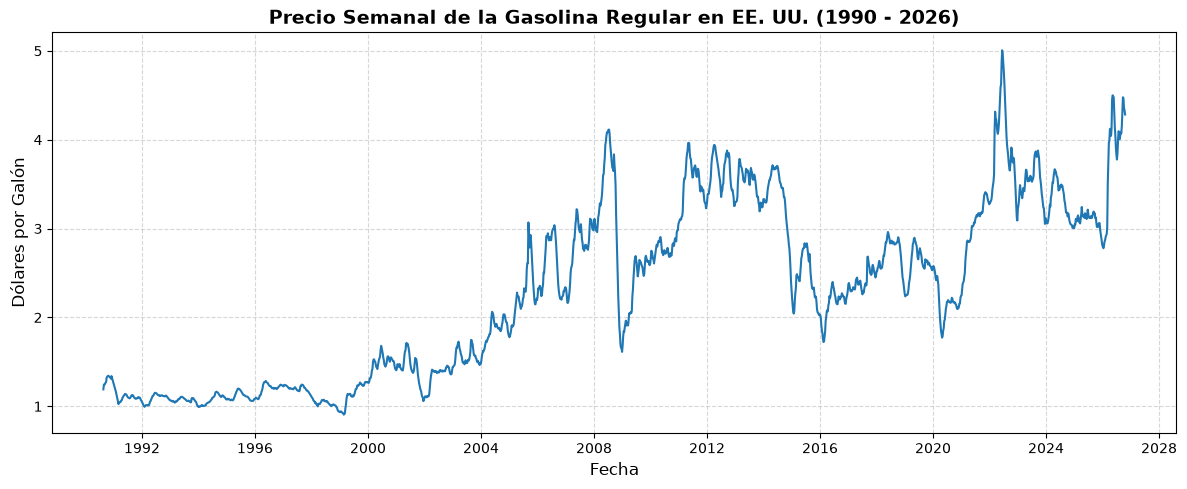

In [9]:
# %% =======================================================
# PASO 1: IDENTIFICACIÓN
# ==========================================================
# Graficar la serie de tiempo en niveles
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['precio_gasolina'], color='#1f77b4', linewidth=1.5)
plt.title('Precio Semanal de la Gasolina Regular en EE. UU. (1990 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Dólares por Galón', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()




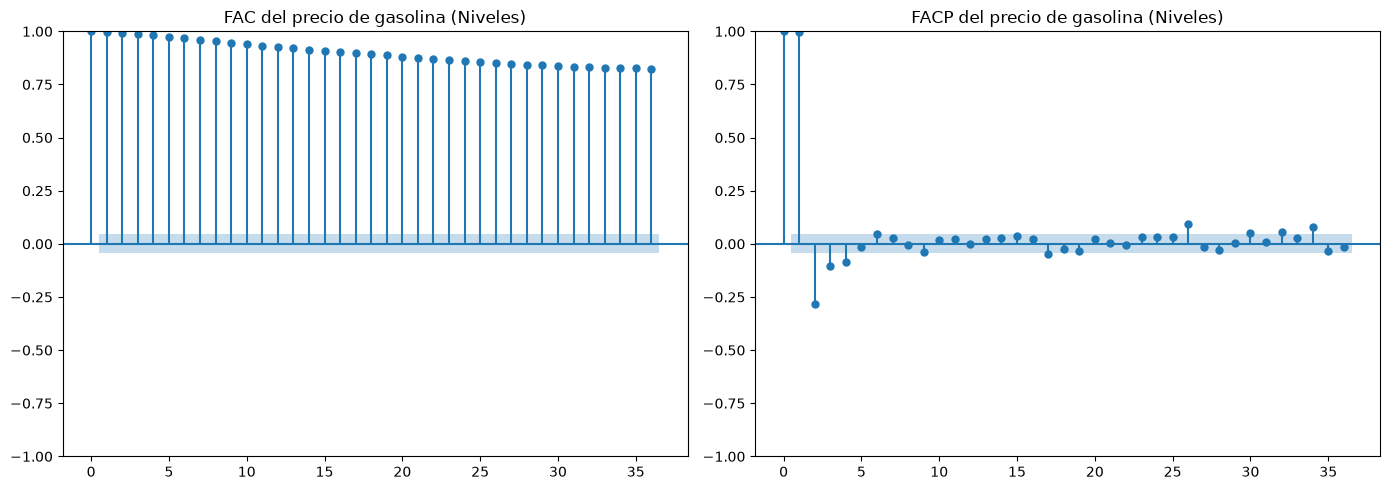

In [10]:
## %% FAC y FACP de la serie original =========================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC del precio de gasolina (Niveles)")

plot_pacf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP del precio de gasolina (Niveles)")

plt.tight_layout()
plt.show()